In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Styling preferences
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (9, 4.5)

# Load existing dataset
df = pd.read_csv('retail_sales_dataset.csv')

# Feature selection for clustering
# Segmenting by Age, basket volume (Quantity), and total spend
features = ['Age', 'Quantity', 'Total Amount']
X = df[features]

# Standardize features so high Total Amount values don't dominate clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Features ready for clustering: {features}")
print(f"Scaled shape: {X_scaled.shape}")

Features ready for clustering: ['Age', 'Quantity', 'Total Amount']
Scaled shape: (1000, 3)


# Customer Segmentation using K-Means Clustering  Task 2

### 1. Project Overview & Data Loading
The objective is to segment customers based on transaction behavior and demographics. We will preprocess numerical features, evaluate optimal clusters using the Elbow Method and Silhouette Analysis, and interpret customer profiles.

**Preprocessing Notes:**
- Features selected: `Age`, `Quantity`, and `Total Amount`.
- Scaled using `StandardScaler` so that `Total Amount` values (which range up to $2,000) do not skew Euclidean distance calculations over smaller-scale variables like `Quantity` (1–4 units).


### 2. Determining Optimal Clusters ($k$)
Evaluating clusters across $k = 2$ to $k = 8$ using both Within-Cluster Sum of Squares (WCSS / Elbow Method) and Silhouette Scores to determine the most coherent grouping.

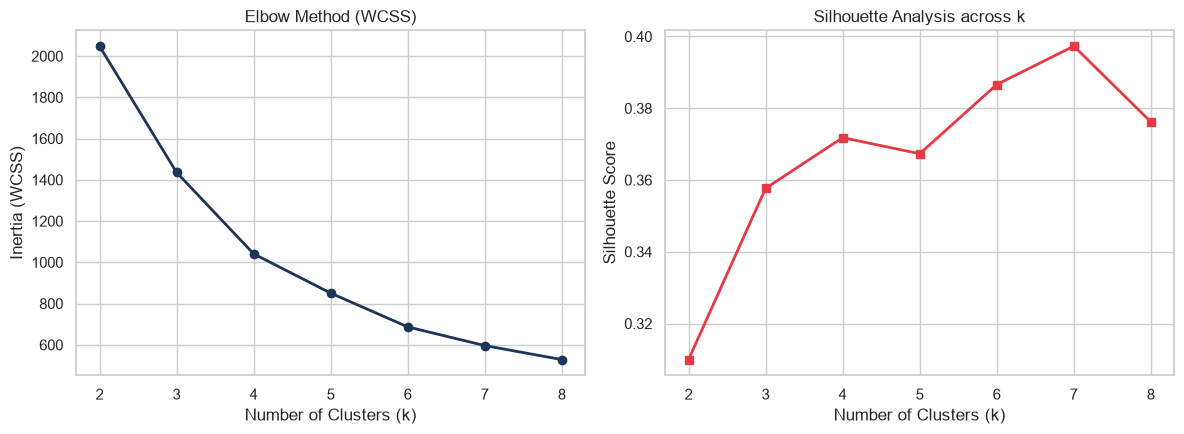

In [2]:
wcss = []
silhouette_scores = []
k_range = range(2, 9)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Plot Elbow and Silhouette evaluation curves side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Elbow curve
axes[0].plot(k_range, wcss, marker='o', color='#1d3557', linewidth=2)
axes[0].set_title('Elbow Method (WCSS)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (WCSS)')

# Silhouette score curve
axes[1].plot(k_range, silhouette_scores, marker='s', color='#e63946', linewidth=2)
axes[1].set_title('Silhouette Analysis across k')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

**Cluster Selection:**
- **Inertia (WCSS):** Shows diminishing reduction in within-cluster variation after $k = 4$ and $k = 5$.
- **Silhouette Score:** Reaches a clear peak at $k = 5$ (~0.40), confirming that five clusters offer the highest cohesion and separation for this dataset. We choose $k = 5$ for model training.


### 3. Model Training & Cluster Profiling
Fitting the K-Means algorithm with $k = 5$, assigning cluster labels back to the original dataset, and examining the mean metrics for each segment.

In [3]:
# Fit K-Means with optimal k=5
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Calculate summary profiles for each cluster
cluster_profile = df.groupby('Cluster').agg({
    'Age': 'mean',
    'Quantity': 'mean',
    'Total Amount': ['mean', 'median', 'count']
}).round(2)

# Flatten MultiIndex columns for clean display
cluster_profile.columns = ['Age (Mean)', 'Quantity (Mean)', 'Total Amount (Mean)', 'Total Amount (Median)', 'Customer Count']
cluster_profile

,Age (Mean),Quantity (Mean),Total Amount (Mean),Total Amount (Median),Customer Count
Cluster,,,,,
0,28.81,3.47,164.29,110.0,140
1,52.79,1.50,251.16,60.0,275
2,39.05,3.47,1396.55,1200.0,203
3,52.84,3.56,182.41,120.0,168
4,28.21,1.46,232.64,60.0,214


**Cluster Profile Insights:**
- **Cluster 2 (High-Value / Premium Shoppers):** Stands out sharply with an average spend of $1,396.55 and basket size of ~3.5 units across 203 customers.
- **Clusters 0 & 4 (Younger Cohort, Avg Age ~28):** Segmented by basket size—Cluster 0 buys larger baskets of cheaper items (3.47 units, $164.29 spend), while Cluster 4 buys fewer units (1.46 units, $232.64 spend).
- **Clusters 1 & 3 (Older Cohort, Avg Age ~53):** Segmented similarly by transaction volume—Cluster 3 purchases larger baskets (3.56 units), while Cluster 1 purchases individual items (1.50 units).


### 4. Cluster Visualizations
Visualizing customer segments across Age vs. Total Amount and Quantity vs. Total Amount to observe cluster separation.

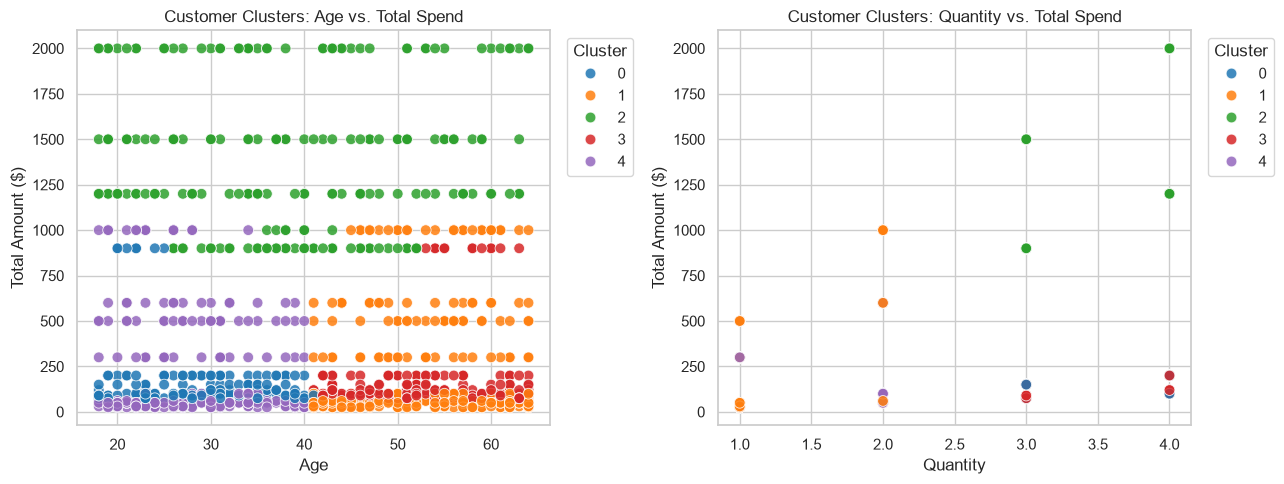

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Age vs Total Amount
sns.scatterplot(
    data=df, 
    x='Age', 
    y='Total Amount', 
    hue='Cluster', 
    palette='tab10', 
    alpha=0.85, 
    s=60, 
    ax=axes[0]
)
axes[0].set_title('Customer Clusters: Age vs. Total Spend')
axes[0].set_ylabel('Total Amount ($)')
axes[0].legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')

# Quantity vs Total Amount
sns.scatterplot(
    data=df, 
    x='Quantity', 
    y='Total Amount', 
    hue='Cluster', 
    palette='tab10', 
    alpha=0.85, 
    s=60, 
    ax=axes[1]
)
axes[1].set_title('Customer Clusters: Quantity vs. Total Spend')
axes[1].set_ylabel('Total Amount ($)')
axes[1].legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

**Observations:**
- **Spend Separation:** Cluster 2 clearly captures the premium spend segment ($1,000+), decoupled from age and focused strictly on high order totals.
- **Demographic Split:** Customers spending below $1,000 are neatly partitioned by age: Clusters 0 and 4 group customers under 40, while Clusters 1 and 3 capture buyers aged 40 and above.
- **Volume Segmentation:** Within the demographic groups, clusters separate further by units purchased (low volume 1–2 items vs. high volume 3–4 items).


### 5. Segment-Specific Business Strategies
1. **Cluster 2 (High-Value VIPs):** Enroll in exclusive VIP rewards programs, early product releases, and concierge customer support to retain loyalty and maintain high ticket values.
2. **Cluster 0 (Young Multi-Item Shoppers):** Offer bundle discounts and cross-category discovery deals (e.g., student-friendly pricing or volume incentives) to keep basket size high.
3. **Cluster 4 (Young Single-Item Buyers):** Implement upselling mechanisms at checkout (e.g., "Add for $10" or free shipping thresholds) to encourage multi-item purchases.
4. **Cluster 1 & 3 (Older Mature Demographic):** Run focused email marketing campaigns highlighting quality, warranties, and reliable essentials suited for higher single-ticket and multi-unit purchases.
